# Digital Image Processing Lab – Lab Task 04
## Geometric Transformations with Custom Inputs

**Name:** YOUR FULL NAME  
**Roll No:** 2024-SE-YOUR_ROLL_NO

### Importing Libraries

In [1]:
import os
import math
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from PIL import Image

### Loading the Image (with checks)

Width : 512
Height: 512
Array shape: (512, 512, 3)


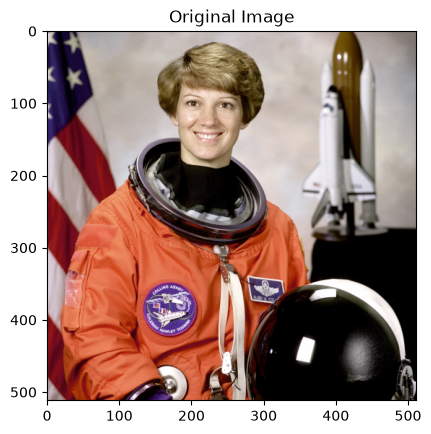

In [ ]:
IMAGE_PATH = "astro_image.png"
# folder for saved results
os.makedirs("outputs", exist_ok=True)      

# 1. the file must exist
if not os.path.exists(IMAGE_PATH):
    raise FileNotFoundError("Image file not found: " + IMAGE_PATH)

# 2. the file must decode (cv.imread gives None if it cannot read it)
bgr = cv.imread(IMAGE_PATH)
if bgr is None:
    raise ValueError("The file could not be decoded as an image")

# 3. width and height must not be zero
if bgr.shape[0] == 0 or bgr.shape[1] == 0:
    raise ValueError("The image has zero width or height")

# OpenCV loads colours as BGR but matplotlib expects RGB, so convert once here.
# From now on every image in this notebook is RGB.
original = cv.cvtColor(bgr, cv.COLOR_BGR2RGB)

# used at the end to prove the original never changed
backup = original.copy()          
       
# shape is (height, width, channels)
height, width = original.shape[:2]         
print("Width :", width)
print("Height:", height)
print("Array shape:", original.shape)

plt.imshow(original)
plt.title("Original Image")
plt.show()

### The `transform` function

One function does all five operations. Settings and rules:

| Operation | Parameters | Rules |
|---|---|---|
| `scale` | `sx`, `sy`, `interpolation` | numbers > 0, output size at least 1 pixel |
| `crop` | `left`, `top`, `right`, `bottom` | whole numbers, `0 <= left < right <= width`, `0 <= top < bottom <= height` |
| `flip` | `direction` | `horizontal`, `vertical` or `both` |
| `translate` | `tx`, `ty` | any number (positive, negative or zero) |
| `rotate` | `angle`, `expand` | any number for angle, `expand` is True or False |

- **Maximum output size:** 4000 pixels for width and for height.
- **No default values:** every parameter must be given, otherwise an error is raised.
- **Directions:** positive `tx` moves right, positive `ty` moves down, positive `angle` rotates **counter-clockwise**.
- Empty areas created by translation/rotation are filled with **black**.

In [ ]:
MAX_SIZE = 4000

INTERPOLATIONS = {
    "nearest": cv.INTER_NEAREST,
    "bilinear": cv.INTER_LINEAR,
    "bicubic": cv.INTER_CUBIC,
    "lanczos": cv.INTER_LANCZOS4,
}

# operation name -> parameters it needs
OPERATIONS = {
    "scale": ["sx", "sy", "interpolation"],
    "crop": ["left", "top", "right", "bottom"],
    "flip": ["direction"],
    "translate": ["tx", "ty"],
    "rotate": ["angle", "expand"],
}


def check_number(name, value):
    # must be a real number (True/False and text are not allowed)
    if isinstance(value, bool) or not isinstance(value, (int, float, np.number)):
        raise ValueError(name + " must be a number, but got " + repr(value))
    # NaN and infinity are not allowed
    if math.isnan(value) or math.isinf(value):
        raise ValueError(name + " must not be NaN or infinity")


def check_size(new_width, new_height):
    if new_width < 1 or new_height < 1:
        raise ValueError("Output image would be empty (" + str(new_width) + "x" + str(new_height) + ")")
    if new_width > MAX_SIZE or new_height > MAX_SIZE:
        raise ValueError("Output " + str(new_width) + "x" + str(new_height) + " is bigger than the maximum " + str(MAX_SIZE) + " pixels")


def transform(image, operation, **params):
    # ---- check the image ----
    if not isinstance(image, np.ndarray):
        raise ValueError("image must be a NumPy array")
    if image.ndim < 2 or image.shape[0] == 0 or image.shape[1] == 0:
        raise ValueError("image is empty")

    # ---- check the operation and its parameters ----
    if operation not in OPERATIONS:
        raise ValueError("Unknown operation: " + str(operation))
    for name in OPERATIONS[operation]:
        if name not in params:
            raise ValueError("Missing parameter: " + name)
    for name in params:
        if name not in OPERATIONS[operation]:
            raise ValueError("Unexpected parameter: " + name)

    h, w = image.shape[:2]

    # ---------------- SCALE ----------------
    if operation == "scale":
        sx = params["sx"]
        sy = params["sy"]
        check_number("sx", sx)
        check_number("sy", sy)
        if sx <= 0 or sy <= 0:
            raise ValueError("Scale factors must be greater than zero")
        method = params["interpolation"]
        if method not in INTERPOLATIONS:
            raise ValueError("Unsupported interpolation: " + str(method))
        new_w = int(round(w * sx))
        new_h = int(round(h * sy))
        check_size(new_w, new_h)
        return cv.resize(image, (new_w, new_h), interpolation=INTERPOLATIONS[method])

    # ---------------- CROP ----------------
    if operation == "crop":
        left = params["left"]
        top = params["top"]
        right = params["right"]
        bottom = params["bottom"]
        for name, value in [("left", left), ("top", top), ("right", right), ("bottom", bottom)]:
            if isinstance(value, bool) or not isinstance(value, (int, np.integer)):
                raise ValueError(name + " must be a whole number, but got " + repr(value))
        if not (0 <= left < right <= w):
            raise ValueError("Need 0 <= left < right <= " + str(w))
        if not (0 <= top < bottom <= h):
            raise ValueError("Need 0 <= top < bottom <= " + str(h))
        # in an array rows come first (y), then columns (x). right/bottom are not included.
        return image[top:bottom, left:right].copy()

    # ---------------- FLIP ----------------
    if operation == "flip":
        direction = params["direction"]
        if direction == "horizontal":
            return cv.flip(image, 1)
        elif direction == "vertical":
            return cv.flip(image, 0)
        elif direction == "both":
            return cv.flip(image, -1)
        else:
            raise ValueError("Direction must be horizontal, vertical or both")

    # ---------------- TRANSLATE ----------------
    if operation == "translate":
        tx = params["tx"]
        ty = params["ty"]
        check_number("tx", tx)
        check_number("ty", ty)
        matrix = np.float32([
            [1, 0, tx],
            [0, 1, ty],
        ])
        # same canvas size (w, h); empty area is black
        return cv.warpAffine(image, matrix, (w, h), borderValue=(0, 0, 0))

    # ---------------- ROTATE ----------------
    if operation == "rotate":
        angle = params["angle"]
        expand = params["expand"]
        check_number("angle", angle)
        if not isinstance(expand, bool):
            raise ValueError("expand must be True or False")

        # centre of the image (pixel numbering starts at 0, so the centre is (size - 1) / 2)
        centre = ((w - 1) / 2, (h - 1) / 2)

        # positive angle = counter-clockwise
        matrix = cv.getRotationMatrix2D(centre, angle, 1.0)  
        out_w = w
        out_h = h

        if expand:
            # size of the box that fits the rotated image
            c = abs(math.cos(math.radians(angle)))
            s = abs(math.sin(math.radians(angle)))
            # round() removes tiny float errors
            out_w = int(math.ceil(round(w * c + h * s, 6)))   
            out_h = int(math.ceil(round(w * s + h * c, 6)))
            check_size(out_w, out_h)
            # move the image so its centre is in the centre of the bigger canvas
            matrix[0, 2] = matrix[0, 2] + (out_w - w) / 2
            matrix[1, 2] = matrix[1, 2] + (out_h - h) / 2

        return cv.warpAffine(image, matrix, (out_w, out_h), borderValue=(0, 0, 0))

### Taking Input from the User

These small functions ask the question again and again (`while True`) until the answer is valid, so a wrong answer never crashes the program.
`get_input` uses the normal `input()`. For this notebook I also pass a ready-made list of answers (`answers`) so the demo runs without waiting for typing.

In [ ]:
def get_input(prompt, answers=None):
    if answers is None:
        return input(prompt)   # real typing
    text = answers.pop(0)      # take the next prepared answer
    print(prompt + text)
    return text


def ask_float(prompt, answers=None):
    while True:
        text = get_input(prompt, answers)
        try:
            value = float(text)
        except ValueError:
            print("   Error: please enter a number.")
            continue
        if math.isnan(value) or math.isinf(value):
            print("   Error: NaN and infinity are not allowed.")
            continue
        return value


def ask_int(prompt, answers=None):
    while True:
        text = get_input(prompt, answers)
        try:
            return int(text)
        except ValueError:
            print("   Error: please enter a whole number.")


def ask_choice(prompt, options, answers=None):
    while True:
        text = get_input(prompt, answers).strip().lower()
        if text in options:
            return text
        print("   Error: choose one of", options)


def ask_yes_no(prompt, answers=None):
    while True:
        text = get_input(prompt, answers).strip().lower()
        if text == "y":
            return True
        if text == "n":
            return False
        print("   Error: answer y or n.")


def run_interactive(image, answers=None):
    # keeps asking until transform() works, then returns (result, operation, params)
    while True:
        op = get_input("Operation (scale/crop/flip/translate/rotate, q = quit): ", answers).strip().lower()
        if op == "q":
            return None
        if op not in OPERATIONS:
            print("   Error: unknown operation.")
            continue

        params = {}
        if op == "scale":
            params["sx"] = ask_float("  Horizontal scale factor: ", answers)
            params["sy"] = ask_float("  Vertical scale factor: ", answers)
            params["interpolation"] = ask_choice("  Interpolation (nearest/bilinear/bicubic/lanczos): ", list(INTERPOLATIONS), answers)
        elif op == "crop":
            params["left"] = ask_int("  Left: ", answers)
            params["top"] = ask_int("  Top: ", answers)
            params["right"] = ask_int("  Right (not included): ", answers)
            params["bottom"] = ask_int("  Bottom (not included): ", answers)
        elif op == "flip":
            params["direction"] = ask_choice("  Direction (horizontal/vertical/both): ", ["horizontal", "vertical", "both"], answers)
        elif op == "translate":
            params["tx"] = ask_float("  tx in pixels (+ = right): ", answers)
            params["ty"] = ask_float("  ty in pixels (+ = down): ", answers)
        elif op == "rotate":
            params["angle"] = ask_float("  Angle in degrees (+ = counter-clockwise): ", answers)
            params["expand"] = ask_yes_no("  Expand canvas? (y/n): ", answers)

        try:
            result = transform(image, op, **params)
            return result, op, params
        except ValueError as error:           # for example a crop outside the image
            print("   Error:", error, "- please enter the values again.")

### Demo of user input (prepared answers, with some wrong ones on purpose)

In [5]:
# 1) unknown operation, then text instead of a number, then valid scale values
answers = ["zoom", "scale", "abc", "1.5", "0.75", "lanczos"]
result, op, params = run_interactive(original, answers)
print("Result size:", result.shape[1], "x", result.shape[0])
print()

# 2) crop that goes outside the image, then corrected
answers = ["crop", "0", "0", "9999", "100", "crop", "100", "50", "400", "300"]
result, op, params = run_interactive(original, answers)
print("Result size:", result.shape[1], "x", result.shape[0])
print()

# 3) infinite angle and wrong y/n answer, then corrected
answers = ["rotate", "inf", "30", "maybe", "y"]
result, op, params = run_interactive(original, answers)
print("Result size:", result.shape[1], "x", result.shape[0])

Operation (scale/crop/flip/translate/rotate, q = quit): zoom
   Error: unknown operation.
Operation (scale/crop/flip/translate/rotate, q = quit): scale
  Horizontal scale factor: abc
   Error: please enter a number.
  Horizontal scale factor: 1.5
  Vertical scale factor: 0.75
  Interpolation (nearest/bilinear/bicubic/lanczos): lanczos
Result size: 768 x 384

Operation (scale/crop/flip/translate/rotate, q = quit): crop
  Left: 0
  Top: 0
  Right (not included): 9999
  Bottom (not included): 100
   Error: Need 0 <= left < right <= 512 - please enter the values again.
Operation (scale/crop/flip/translate/rotate, q = quit): crop
  Left: 100
  Top: 50
  Right (not included): 400
  Bottom (not included): 300
Result size: 300 x 250

Operation (scale/crop/flip/translate/rotate, q = quit): rotate
  Angle in degrees (+ = counter-clockwise): inf
   Error: NaN and infinity are not allowed.
  Angle in degrees (+ = counter-clockwise): 30
  Expand canvas? (y/n): maybe
   Error: answer y or n.
  Expan

To type your own values, set `RUN_LIVE = True` and run the next cell.

In [6]:
RUN_LIVE = False

if RUN_LIVE:
    output = run_interactive(original)      # no answers list -> uses input()
    if output is not None:
        result, op, params = output
        plt.imshow(result)
        plt.title(op + " " + str(params) + "\nOutput size: " + str(result.shape[1]) + "x" + str(result.shape[0]), fontsize=8)
        plt.show()
else:
    print("Live input skipped.")

Live input skipped.


### Demonstration of Every Operation

Each figure shows the original and the results. The title of each result shows the operation, its parameters and the output size. All results are saved in the `outputs` folder.

In [7]:
def demo(cases):
    # cases is a list of (file name, operation, parameters)
    fig, axes = plt.subplots(1, len(cases) + 1, figsize=(4 * (len(cases) + 1), 4.8))

    axes[0].imshow(original)
    axes[0].set_title("Original\nSize: " + str(width) + "x" + str(height), fontsize=8)

    for ax, (filename, op, params) in zip(axes[1:], cases):
        result = transform(original, op, **params)
        ax.imshow(result)
        ax.set_title(op + " " + str(params) + "\nOutput size: " + str(result.shape[1]) + "x" + str(result.shape[0]), fontsize=8)
        Image.fromarray(result).save("outputs/" + filename + ".png")    # save the result

    plt.tight_layout()
    plt.show()

#### Scaling

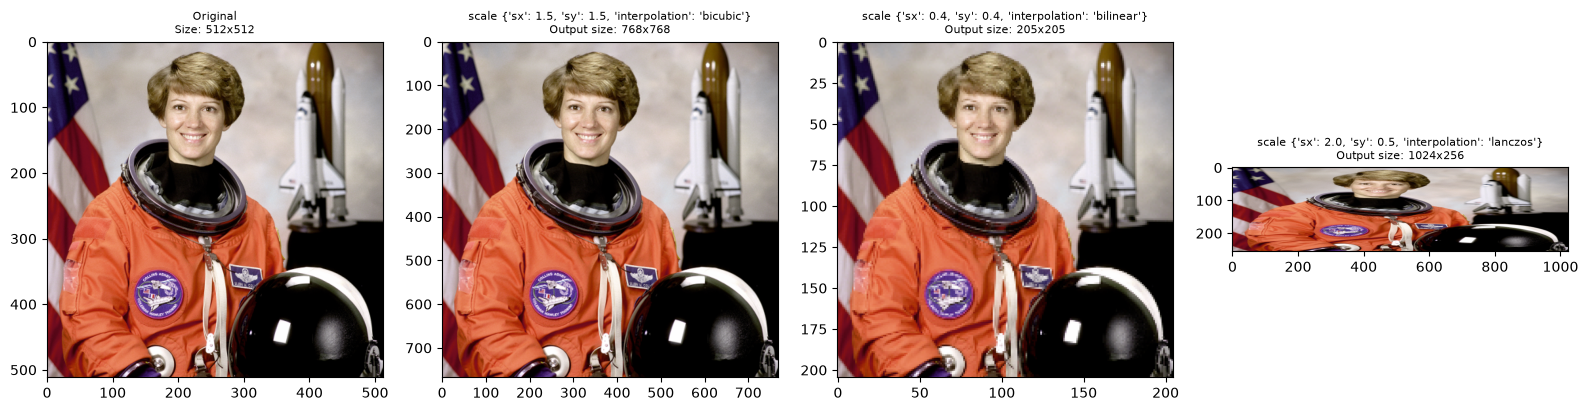

In [8]:
demo([
    ("scale_enlarge_1.5x1.5", "scale", {"sx": 1.5, "sy": 1.5, "interpolation": "bicubic"}),
    ("scale_reduce_0.4x0.4", "scale", {"sx": 0.4, "sy": 0.4, "interpolation": "bilinear"}),
    ("scale_nonproportional_2x0.5", "scale", {"sx": 2.0, "sy": 0.5, "interpolation": "lanczos"}),
])

When `sx` and `sy` are equal the shapes stay natural (proportional scaling). When they are different (2.0 and 0.5) the image is stretched sideways and squashed vertically, so the shape looks distorted (non-proportional scaling).

#### Cropping

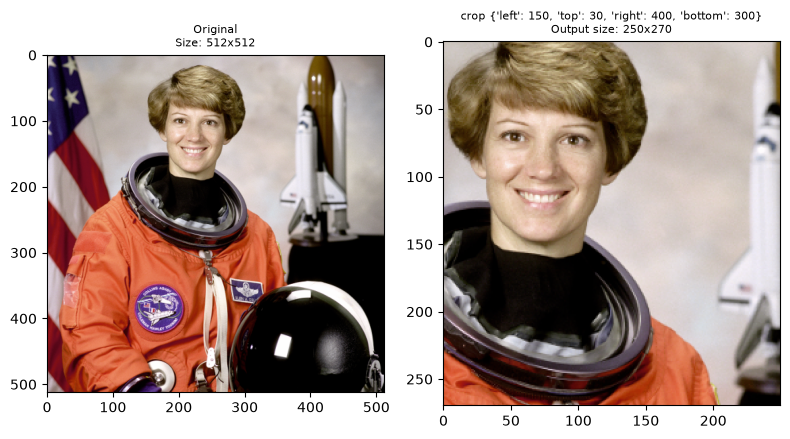

In [9]:
demo([
    ("crop_150_30_400_300", "crop", {"left": 150, "top": 30, "right": 400, "bottom": 300}),
])

#### Flipping

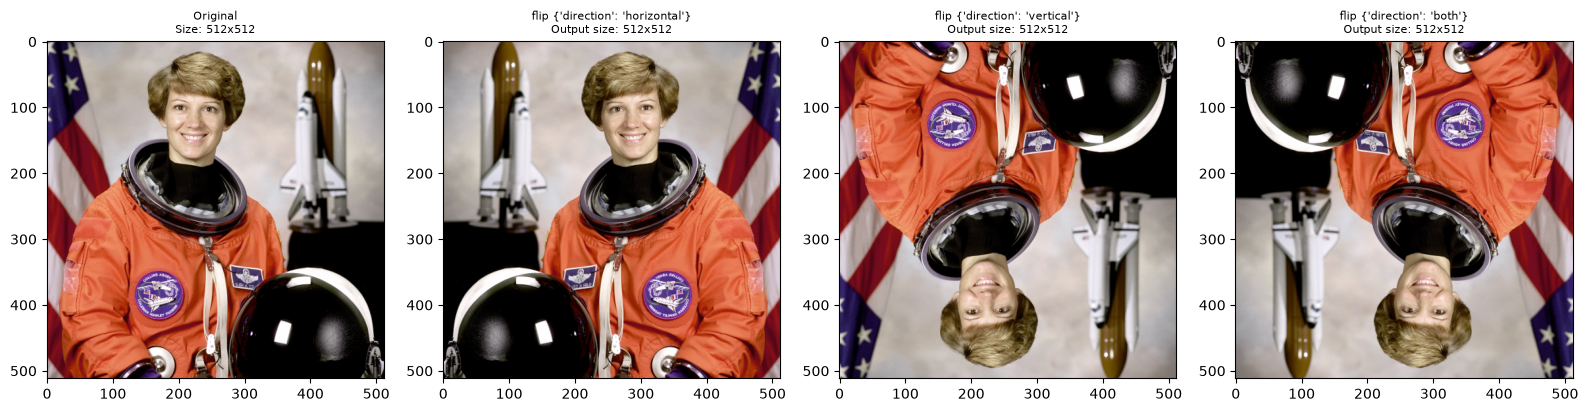

In [10]:
demo([
    ("flip_horizontal", "flip", {"direction": "horizontal"}),
    ("flip_vertical", "flip", {"direction": "vertical"}),
    ("flip_both", "flip", {"direction": "both"}),
])

#### Translation

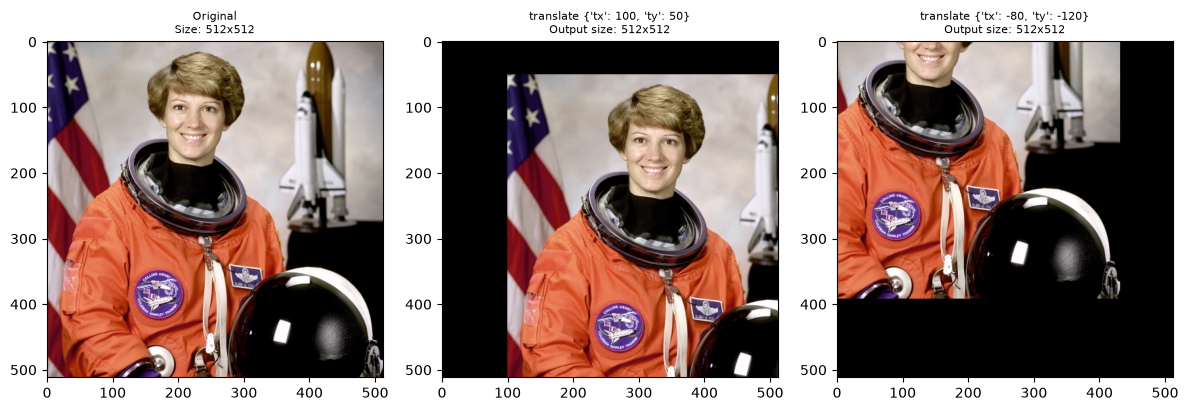

In [11]:
demo([
    ("translate_100_50", "translate", {"tx": 100, "ty": 50}),
    ("translate_-80_-120", "translate", {"tx": -80, "ty": -120}),
])

The canvas size stays the same. Pixels that move outside the canvas are **clipped** (lost), and the area that is uncovered on the other side is filled with black.

#### Rotation

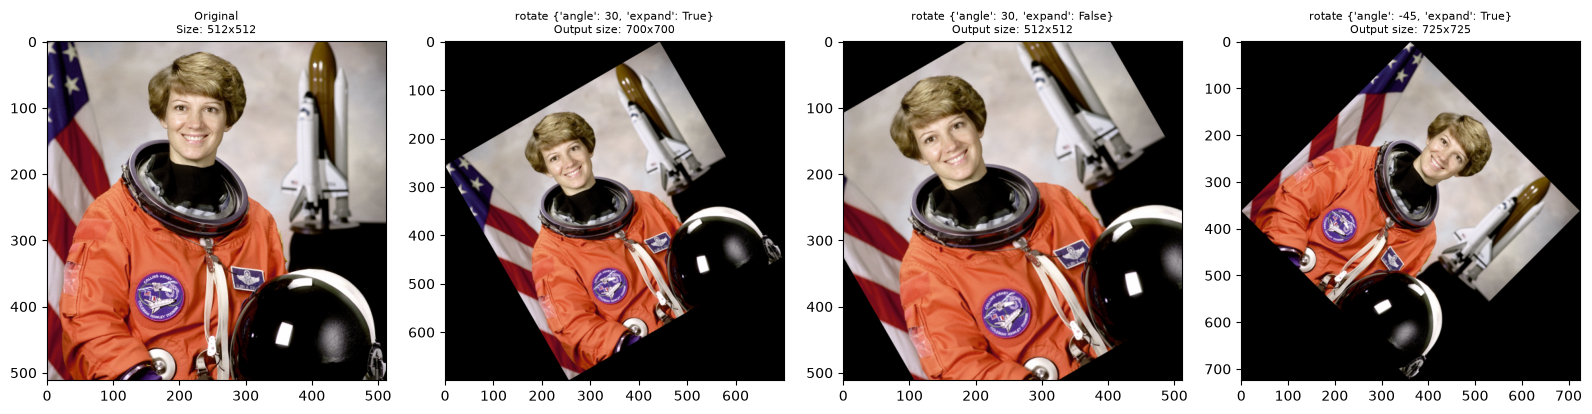

In [12]:
demo([
    ("rotate_+30_expand", "rotate", {"angle": 30, "expand": True}),
    ("rotate_+30_no_expand", "rotate", {"angle": 30, "expand": False}),
    ("rotate_-45_expand", "rotate", {"angle": -45, "expand": True}),
])

A **positive** angle rotates **counter-clockwise**, a negative angle rotates clockwise. With `expand=True` the canvas becomes bigger so the whole image fits. With `expand=False` the canvas stays the same and the corners are cut off.

### Interpolation Comparison on an Enlarged Patch

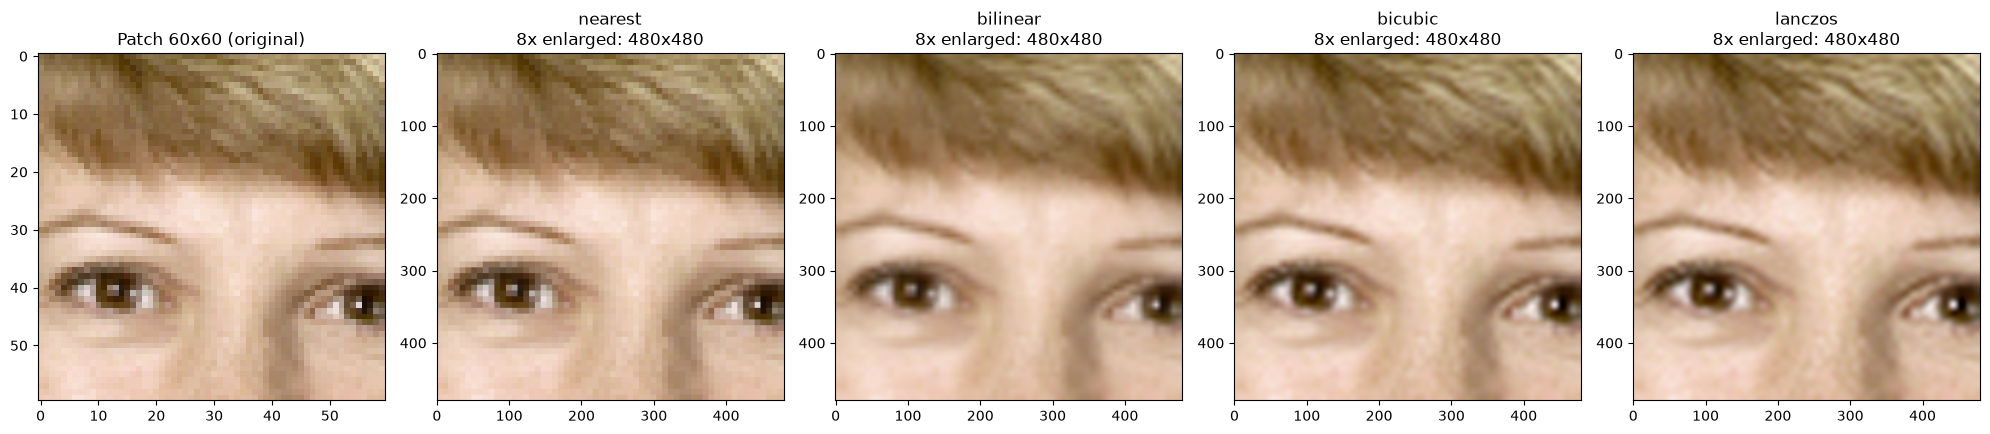

In [13]:
patch = transform(original, "crop", left=190, top=60, right=250, bottom=120)    # 60x60 patch

fig, axes = plt.subplots(1, 5, figsize=(20, 4.8))
axes[0].imshow(patch)
axes[0].set_title("Patch 60x60 (original)")

for ax, method in zip(axes[1:], INTERPOLATIONS):
    big = transform(patch, "scale", sx=8, sy=8, interpolation=method)
    ax.imshow(big)
    ax.set_title(method + "\n8x enlarged: " + str(big.shape[1]) + "x" + str(big.shape[0]))
    Image.fromarray(big).save("outputs/interpolation_" + method + ".png")

plt.tight_layout()
plt.show()

**Observations**
- **Nearest:** blocky/pixelated edges (it just copies the closest pixel), but very fast.
- **Bilinear:** smooth, but a bit blurry (average of 4 pixels).
- **Bicubic:** smoother than nearest and a little sharper than bilinear (uses 16 pixels).
- **Lanczos:** the sharpest edges, but it can create a slight halo near strong edges.

### Rejected Inputs (at least one for each operation)

In [14]:
bad_cases = [
    ("unknown operation", original, "skew", {"k": 1}),
    ("scale: zero factor", original, "scale", {"sx": 0, "sy": 1, "interpolation": "bilinear"}),
    ("scale: negative factor", original, "scale", {"sx": -2, "sy": 1, "interpolation": "bilinear"}),
    ("scale: NaN factor", original, "scale", {"sx": float("nan"), "sy": 1, "interpolation": "bilinear"}),
    ("scale: empty output", original, "scale", {"sx": 0.0005, "sy": 1, "interpolation": "bilinear"}),
    ("scale: too large", original, "scale", {"sx": 50, "sy": 50, "interpolation": "bilinear"}),
    ("scale: bad interpolation", original, "scale", {"sx": 2, "sy": 2, "interpolation": "spline"}),
    ("scale: missing parameter", original, "scale", {"sx": 2, "sy": 2}),
    ("crop: right smaller than left", original, "crop", {"left": 300, "top": 0, "right": 100, "bottom": 100}),
    ("crop: outside the image", original, "crop", {"left": 0, "top": 0, "right": width + 1, "bottom": 100}),
    ("crop: negative coordinate", original, "crop", {"left": -5, "top": 0, "right": 100, "bottom": 100}),
    ("crop: not a whole number", original, "crop", {"left": 0, "top": 0, "right": 100.5, "bottom": 100}),
    ("flip: unsupported direction", original, "flip", {"direction": "diagonal"}),
    ("translate: infinite offset", original, "translate", {"tx": float("inf"), "ty": 0}),
    ("translate: text offset", original, "translate", {"tx": "ten", "ty": 0}),
    ("rotate: text angle", original, "rotate", {"angle": "ninety", "expand": True}),
    ("rotate: NaN angle", original, "rotate", {"angle": float("nan"), "expand": True}),
    ("rotate: expand is not True/False", original, "rotate", {"angle": 45, "expand": "maybe"}),
    ("rotate: expanded canvas too large", np.zeros((3900, 3900, 3), np.uint8), "rotate", {"angle": 45, "expand": True}),
]

for description, img, op, params in bad_cases:
    try:
        transform(img, op, **params)
        print("NOT REJECTED ->", description)
    except ValueError as error:
        print("Rejected:", description, "->", error)

Rejected: unknown operation -> Unknown operation: skew
Rejected: scale: zero factor -> Scale factors must be greater than zero
Rejected: scale: negative factor -> Scale factors must be greater than zero
Rejected: scale: NaN factor -> sx must not be NaN or infinity
Rejected: scale: empty output -> Output image would be empty (0x512)
Rejected: scale: too large -> Output 25600x25600 is bigger than the maximum 4000 pixels
Rejected: scale: bad interpolation -> Unsupported interpolation: spline
Rejected: scale: missing parameter -> Missing parameter: interpolation
Rejected: crop: right smaller than left -> Need 0 <= left < right <= 512
Rejected: crop: outside the image -> Need 0 <= left < right <= 512
Rejected: crop: negative coordinate -> Need 0 <= left < right <= 512
Rejected: crop: not a whole number -> right must be a whole number, but got 100.5
Rejected: flip: unsupported direction -> Direction must be horizontal, vertical or both
Rejected: translate: infinite offset -> tx must not be N

### Identity Checks

In [15]:
def same(a, b):
    return a.shape == b.shape and np.array_equal(a, b)

checks = [
    ("Translate tx=0, ty=0", "same as original", same(transform(original, "translate", tx=0, ty=0), original)),
    ("Scale 1 x 1 (nearest)", "same as original", same(transform(original, "scale", sx=1, sy=1, interpolation="nearest"), original)),
    ("Scale 1 x 1 (bilinear)", "same as original", same(transform(original, "scale", sx=1, sy=1, interpolation="bilinear"), original)),
    ("Scale 1 x 1 (bicubic)", "same as original", same(transform(original, "scale", sx=1, sy=1, interpolation="bicubic"), original)),
    ("Scale 1 x 1 (lanczos)", "same as original", same(transform(original, "scale", sx=1, sy=1, interpolation="lanczos"), original)),
    ("Rotate 0 deg (expand=False)", "same as original", same(transform(original, "rotate", angle=0, expand=False), original)),
    ("Rotate 0 deg (expand=True)", "same as original", same(transform(original, "rotate", angle=0, expand=True), original)),
    ("Crop whole image", "same as original", same(transform(original, "crop", left=0, top=0, right=width, bottom=height), original)),
    ("Flip horizontal twice", "same as original", same(transform(transform(original, "flip", direction="horizontal"), "flip", direction="horizontal"), original)),
    ("Rotate +90 then -90 (expand)", "same as original", same(transform(transform(original, "rotate", angle=90, expand=True), "rotate", angle=-90, expand=True), original)),
    ("Original unchanged at the end", "same as backup", same(original, backup)),
]

print(f"{'Check':35} {'Expected':20} {'Actual':12} Result")
print("-" * 80)
for name, expected, ok in checks:
    actual = "same" if ok else "different"
    result = "Pass" if ok else "Fail"
    print(f"{name:35} {expected:20} {actual:12} {result}")

Check                               Expected             Actual       Result
--------------------------------------------------------------------------------
Translate tx=0, ty=0                same as original     same         Pass
Scale 1 x 1 (nearest)               same as original     same         Pass
Scale 1 x 1 (bilinear)              same as original     same         Pass
Scale 1 x 1 (bicubic)               same as original     same         Pass
Scale 1 x 1 (lanczos)               same as original     same         Pass
Rotate 0 deg (expand=False)         same as original     same         Pass
Rotate 0 deg (expand=True)          same as original     same         Pass
Crop whole image                    same as original     same         Pass
Flip horizontal twice               same as original     same         Pass
Rotate +90 then -90 (expand)        same as original     same         Pass
Original unchanged at the end       same as backup       same         Pass


### Explanations

**Image coordinates vs array indexing.** In image coordinates a point is written as **(x, y)**: x goes to the right (columns) and y goes down (rows), and (0, 0) is the top-left corner. In a NumPy array the order is reversed: `image[row, column]` which is `image[y, x]`, and `image.shape` is `(height, width, channels)`. So the width is `shape[1]`. This is why cropping is written `image[top:bottom, left:right]`, while OpenCV functions like `cv.resize` and `cv.warpAffine` ask for the size as `(width, height)`.

**Aspect-ratio distortion.** The aspect ratio is width / height. If `sx` and `sy` are different, the image is stretched more in one direction, so shapes look wider or taller than they really are. Using the same factor for both keeps the aspect ratio.

**Rotation canvas expansion.** If the canvas stays the same size, the corners of the rotated image go outside and are cut off. With expansion the canvas is made bigger (`w*|cos| + h*|sin|` by `w*|sin| + h*|cos|`) so the complete image fits, and the extra corners are filled with black.

**Translation clipping.** The canvas size does not change, so pixels that move past the border are lost (clipped). The area that opens on the opposite side has no pixels, so it is filled with black background.

### Saved Files

In [16]:
files = sorted(os.listdir("outputs"))
print(len(files), "images saved in the outputs folder:")
for name in files:
    print("  ", name)

31 images saved in the outputs folder:
   crop_150_30_400_300.png
   crop_full_image.png
   flip_both.png
   flip_horizontal.png
   flip_vertical.png
   interp_patch_bicubic.png
   interp_patch_bilinear.png
   interp_patch_lanczos.png
   interp_patch_nearest.png
   interpolation_bicubic.png
   interpolation_bilinear.png
   interpolation_lanczos.png
   interpolation_nearest.png
   rotate_+30_expand.png
   rotate_+30_expand_false.png
   rotate_+30_expand_true.png
   rotate_+30_no_expand.png
   rotate_-45_expand.png
   rotate_-45_expand_true.png
   rotate_0_expand_false.png
   scale_enlarge_1.5x1.5.png
   scale_enlarge_proportional_1.5x1.5_bicubic.png
   scale_nonproportional_2.0x0.5_lanczos.png
   scale_nonproportional_2x0.5.png
   scale_reduce_0.4x0.4.png
   scale_reduce_proportional_0.4x0.4_bilinear.png
   translate_-80_-120.png
   translate_100_50.png
   translate_tx-80_ty-120.png
   translate_tx0_ty0.png
   translate_tx100_ty50.png
